# Yemen MarketShield AI — التحليل الأولي

**مشروع بحثي:** دراسة التنبؤ بصدمات أسعار الغذاء في اليمن باستخدام أسعار الغذاء والصرف والطاقة.

هذا الدفتر يقرأ ملفات البنك الدولي الثلاثة، ويفحص مفاتيحها وجودتها، ثم يجري تجربتين أوليتين: (1) تنبؤ بسعر القمح المقدّر للشهر، و(2) تصنيف ما إذا كان سعر القمح المقدّر سيرتفع بأكثر من 5% في الشهر التالي.

> **تنبيه علمي مهم:** ملفات Real-Time Prices التابعة للبنك الدولي تجمع بين قياسات مباشرة وتقديرات تعلم آلة للقيم المفقودة، كما أن أعمدة `o_`, `h_`, `l_`, `c_` هي تقديرات شهرية Open/High/Low/Close. لذلك فإن `c_wheat` هدفه في التجربة هو *تقدير الإغلاق الشهري في قاعدة البيانات*، وليس سعرًا ميدانيًا مستقلًا مؤكدًا. سنستخدم النتائج لفحص المنهجية، ولا نزعم أن النموذج يتنبأ بالسعر الحقيقي في كل سوق دون تقييم مستقل. المصدر الرسمي يشرح ذلك هنا: [وصف بيانات الغذاء](https://microdata.worldbank.org/catalog/4508) و[وصف بيانات الطاقة](https://microdata.worldbank.org/catalog/6133/study-description).

إصدار الملفات المستخدم في هذه الدراسة هو `2026-03-24`، والفترة حتى مارس 2026. احتفظ بالإصدار نفسه عند إعادة التجارب لتظل النتائج قابلة للتكرار.

## 1. تحميل ملفات ZIP الثلاثة

In [1]:
# In Google Colab, upload the three official ZIP archives when prompted.
# In local Jupyter, place those same ZIP files beside this notebook before running it.
from pathlib import Path
import io, zipfile, os
import pandas as pd
import numpy as np

EXPECTED = {
    "food": "YEM_RTFP_mkt_2009_2026-03-24.csv",
    "fx": "YEM_RTFX_mkt_2009_2026-03-24.csv",
    "energy": "YEM_RTEP_mkt_2009_2026-03-24.csv",
}

try:
    from google.colab import files
    print("Upload the three World Bank ZIP archives listed in the project README.")
    uploaded = files.upload()
except ImportError:
    expected_zips = [
        Path("YEM_RTFP_mkt_2009_2026-03-24.zip"),
        Path("YEM_RTFX_mkt_2009_2026-03-24.zip"),
        Path("YEM_RTEP_mkt_2009_2026-03-24.zip"),
    ]
    missing = [str(p) for p in expected_zips if not p.is_file()]
    if missing:
        raise FileNotFoundError(
            "Missing source ZIP files: " + ", ".join(missing) +
            ". Download them from the World Bank catalog links in README.md."
        )
    uploaded = {p.name: p.read_bytes() for p in expected_zips}

def read_csv_from_uploaded_zip(expected_csv):
    matches = []
    for filename, contents in uploaded.items():
        if filename.lower().endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(contents)) as zf:
                csv_names = [n for n in zf.namelist() if n.lower().endswith('.csv')]
                for name in csv_names:
                    if os.path.basename(name) == expected_csv:
                        with zf.open(name) as f:
                            matches.append(pd.read_csv(f, low_memory=False))
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one ZIP containing {expected_csv}; found {len(matches)}")
    return matches[0]

food = read_csv_from_uploaded_zip(EXPECTED['food'])
fx = read_csv_from_uploaded_zip(EXPECTED['fx'])
energy = read_csv_from_uploaded_zip(EXPECTED['energy'])
for df in (food, fx, energy):
    df['price_date'] = pd.to_datetime(df['price_date'])
print('Food:', food.shape, '| FX:', fx.shape, '| Energy:', energy.shape)


Food: (5175, 165) | FX: (5175, 40) | Energy: (5175, 34)


## 2. فحص بنية البيانات والتغطية

In [2]:
def quick_summary(name, df):
    print(f"\n{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print('Period:', df['price_date'].min().date(), 'to', df['price_date'].max().date())
    print('Unique geo_id:', df['geo_id'].nunique())
    print('Unique market names:', df['mkt_name'].nunique())
    print('Duplicate (geo_id, price_date) keys:', df.duplicated(['geo_id','price_date']).sum())
    print('Markets:', sorted(df['mkt_name'].dropna().unique()))

quick_summary('Food', food)
quick_summary('Exchange rate', fx)
quick_summary('Energy', energy)


Food: 5,175 rows × 165 columns
Period: 2009-01-01 to 2026-03-01
Unique geo_id: 25
Unique market names: 25
Duplicate (geo_id, price_date) keys: 0
Markets: ['Addaleh Town - Al Tadamhn', 'Aden City', 'Al Bayda City', 'Al Ghaidha', 'Al Hawtah- Main road - Back Street', 'Al Hazum', 'Al Jabeen', 'Alduhamih', 'Alsuail', 'Amran City', 'Central Ataq - Al Nasib neighbour - Darhim', 'Dhamar City', 'Haradh Town', 'Ibb City', 'Jihana Almarkazi', 'Mahweet City', 'Marib City - Al mujmaa', 'Market Average', 'Mukalla City', "Sa'ada City", "Sana'a City", 'Sayoun City', 'Soqatra (Hudaibo)', 'Taiz City', 'Zungubar City']

Exchange rate: 5,175 rows × 40 columns
Period: 2009-01-01 to 2026-03-01
Unique geo_id: 25
Unique market names: 25
Duplicate (geo_id, price_date) keys: 0
Markets: ['Addaleh Town - Al Tadamhn', 'Aden City', 'Al Bayda City', 'Al Ghaidha', 'Al Hawtah- Main road - Back Street', 'Al Hazum', 'Al Jabeen', 'Alduhamih', 'Alsuail', 'Amran City', 'Central Ataq - Al Nasib neighbour - Darhim', 'Dhama

**ملاحظة عن عدد الأسواق:** تحتوي البيانات على 25 قيمة `geo_id`، وتشمل 24 سوقًا محليًا بالإضافة إلى سجل `Market Average`، ولذلك لا نعامل المتوسط الوطني بوصفه سوقًا محليًا عاديًا عند تحليل الأسواق الفردية.

## 3. التأكد من إمكانية الدمج

In [3]:
KEY = ['geo_id', 'price_date']
key_sets = {
    'food': set(map(tuple, food[KEY].astype(str).to_numpy())),
    'fx': set(map(tuple, fx[KEY].astype(str).to_numpy())),
    'energy': set(map(tuple, energy[KEY].astype(str).to_numpy())),
}
print('Food = FX keys:', key_sets['food'] == key_sets['fx'])
print('Food = Energy keys:', key_sets['food'] == key_sets['energy'])
print('Shared key count:', len(key_sets['food'] & key_sets['fx'] & key_sets['energy']))

# نحتفظ فقط بالأعمدة اللازمة للتجارب الأولى لتجنب تكرار أعمدة التعريف.
food_keep = ['geo_id','price_date','mkt_name','adm1_name','lat','lon','c_wheat','wheat','c_wheat_flour','c_rice','c_sugar','c_food_price_index','trust_wheat','data_coverage_recent','index_confidence_score','spatially_interpolated']
fx_keep = ['geo_id','price_date','c_exchange_rate_unofficial','exchange_rate_unofficial','trust_exchange_rate_unofficial','c_milling_cost_wheat']
energy_keep = ['geo_id','price_date','c_fuel_diesel','fuel_diesel','c_fuel_gas','fuel_gas','c_fuel_petrol_gasoline','fuel_petrol_gasoline','trust_fuel_diesel','spatially_interpolated']
merged = food[[c for c in food_keep if c in food.columns]].merge(
    fx[[c for c in fx_keep if c in fx.columns]], on=KEY, how='left', validate='one_to_one', suffixes=('','_fx')
).merge(
    energy[[c for c in energy_keep if c in energy.columns]], on=KEY, how='left', validate='one_to_one', suffixes=('','_energy')
)
print('Merged shape:', merged.shape)
print('Missing values in key estimates:')
print(merged[['c_wheat','c_exchange_rate_unofficial','c_fuel_diesel']].isna().sum())
merged.head()

Food = FX keys: True
Food = Energy keys: True
Shared key count: 5175
Merged shape: (5175, 28)
Missing values in key estimates:
c_wheat                       0
c_exchange_rate_unofficial    0
c_fuel_diesel                 0
dtype: int64


,geo_id,price_date,mkt_name,adm1_name,lat,lon,c_wheat,wheat,c_wheat_flour,c_rice,c_sugar,c_food_price_index,trust_wheat,data_coverage_recent,index_confidence_score,spatially_interpolated,c_exchange_rate_unofficial,exchange_rate_unofficial,trust_exchange_rate_unofficial,c_milling_cost_wheat,c_fuel_diesel,fuel_diesel,c_fuel_gas,fuel_gas,c_fuel_petrol_gasoline,fuel_petrol_gasoline,trust_fuel_diesel,spatially_interpolated_energy
0,gid_137000000447300000,2009-01-01,Addaleh Town - Al Tadamhn,Al Dhale'e,13.7,44.73,87.48,NaN,103.69,250.06,182.76,0.68,9.2,25.37,0.96,0,264.38,NaN,9.3,763.46,102.13,NaN,2869.95,NaN,149.53,NaN,8.4,0
1,gid_137000000447300000,2009-02-01,Addaleh Town - Al Tadamhn,Al Dhale'e,13.7,44.73,84.47,NaN,102.43,250.41,180.67,0.67,9.2,25.37,0.96,0,264.57,NaN,9.3,757.16,100.59,NaN,2822.65,NaN,143.87,NaN,8.4,0
2,gid_137000000447300000,2009-03-01,Addaleh Town - Al Tadamhn,Al Dhale'e,13.7,44.73,85.09,NaN,103.68,247.30,181.63,0.67,9.2,25.37,0.96,0,264.87,NaN,9.3,761.35,101.43,NaN,2834.91,NaN,147.37,NaN,8.4,0
3,gid_137000000447300000,2009-04-01,Addaleh Town - Al Tadamhn,Al Dhale'e,13.7,44.73,86.55,NaN,104.30,249.71,183.10,0.68,9.2,25.37,0.96,0,264.70,NaN,9.3,767.42,102.24,NaN,2873.90,NaN,152.24,NaN,8.4,0
4,gid_137000000447300000,2009-05-01,Addaleh Town - Al Tadamhn,Al Dhale'e,13.7,44.73,78.15,NaN,99.82,237.83,175.24,0.66,9.2,25.37,0.96,0,264.81,NaN,9.3,741.49,99.67,NaN,2743.65,NaN,140.69,NaN,8.4,0


## 4. رسم أولي لأسعار القمح

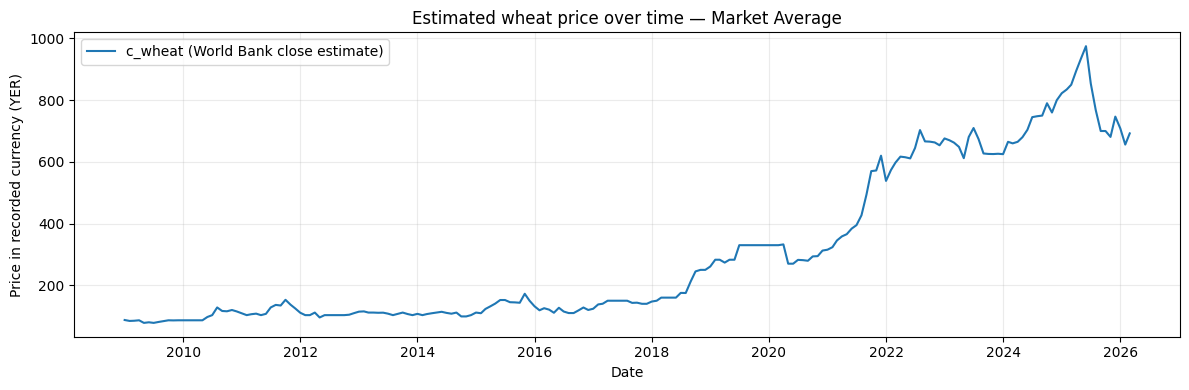

Market used: Market Average


In [4]:
import matplotlib.pyplot as plt
market = 'Market Average'
plot_df = merged.loc[merged['mkt_name'].eq(market)].sort_values('price_date')
if plot_df.empty:
    # إن لم يكن متوسط السوق موجودًا نختار السوق الأكثر اكتمالًا
    market = merged['mkt_name'].value_counts().index[0]
    plot_df = merged.loc[merged['mkt_name'].eq(market)].sort_values('price_date')
plt.figure(figsize=(12,4))
plt.plot(plot_df['price_date'], plot_df['c_wheat'], label='c_wheat (World Bank close estimate)')
plt.title(f'Estimated wheat price over time — {market}')
plt.xlabel('Date'); plt.ylabel('Price in recorded currency (YER)')
plt.grid(True, alpha=0.25); plt.legend(); plt.tight_layout(); plt.show()
print('Market used:', market)

## 5. التجربة الأولى: توقع مستوى سعر القمح للشهر

نستخدم تقسيمًا زمنيًا: التدريب قبل يناير 2022 والاختبار من يناير 2022 حتى آخر تاريخ متاح. النموذج لا يرى ميزات من الشهر المستهدف إلا السعر السابق والخصائص المحسوبة من الماضي. خط الأساس `lag-1` يفترض أن سعر الشهر القادم يساوي آخر تقدير إغلاق متاح؛ وهذا خط أساس بسيط لكنه قوي في كثير من السلاسل السعرية.

In [5]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

model_data = merged.sort_values(['geo_id','price_date']).copy()
lag_series = ['c_wheat','c_wheat_flour','c_rice','c_sugar','c_exchange_rate_unofficial','c_fuel_diesel','c_fuel_gas','c_fuel_petrol_gasoline','c_milling_cost_wheat']
for col in lag_series:
    if col in model_data.columns:
        for lag in (1,2,3,12):
            model_data[f'{col}_lag{lag}'] = model_data.groupby('geo_id')[col].shift(lag)
model_data['month_num'] = model_data['price_date'].dt.month
model_data = model_data.dropna(subset=['c_wheat','c_wheat_lag1']).copy()
train = model_data[model_data['price_date'] < '2022-01-01']
test = model_data[model_data['price_date'] >= '2022-01-01']
features = [f'{c}_lag{lag}' for c in lag_series for lag in (1,2,3,12) if f'{c}_lag{lag}' in model_data.columns] + ['month_num']

def regression_metrics(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
            'WAPE': np.sum(np.abs(y_true-y_pred)) / np.sum(np.abs(y_true))}

results = []
results.append({'Model':'Naive: previous month', **regression_metrics(test['c_wheat'].to_numpy(), test['c_wheat_lag1'].to_numpy())})
# تعلّم التغير من الشهر السابق ثم نضيفه إلى سعر الشهر السابق
for name, estimator in [
    ('Random Forest on price level', RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.8, random_state=42, n_jobs=-1)),
    ('Gradient Boosting on price change', GradientBoostingRegressor(n_estimators=250, learning_rate=0.03, max_depth=2, loss='huber', random_state=42)),
]:
    target_col = 'c_wheat' if name.startswith('Random') else 'delta_target'
    if target_col == 'delta_target':
        model_data['delta_target'] = model_data['c_wheat'] - model_data['c_wheat_lag1']
        train = model_data[(model_data['price_date'] < '2022-01-01') & model_data['delta_target'].notna()]
        test = model_data[(model_data['price_date'] >= '2022-01-01') & model_data['delta_target'].notna()]
    else:
        train = model_data[model_data['price_date'] < '2022-01-01']
        test = model_data[model_data['price_date'] >= '2022-01-01']
    pipe = make_pipeline(SimpleImputer(strategy='median'), estimator)
    pipe.fit(train[features], train[target_col])
    raw_pred = pipe.predict(test[features])
    pred = test['c_wheat_lag1'].to_numpy() + raw_pred if target_col == 'delta_target' else raw_pred
    results.append({'Model':name, **regression_metrics(test['c_wheat'].to_numpy(), pred)})

pd.DataFrame(results).round(3)

,Model,MAE,RMSE,WAPE
0,Naive: previous month,22.379,38.425,0.038
1,Random Forest on price level,66.865,101.874,0.114
2,Gradient Boosting on price change,27.469,42.989,0.047


### تفسير النتائج

لا نختار النموذج الأكثر تعقيدًا تلقائيًا. إذا كان خط الأساس (السعر السابق) أفضل، فهذا يعني أن نماذجنا الأولية لم تثبت بعد قيمة إضافية للتنبؤ بمستوى السعر. عندئذٍ ندرس التنبؤ بالتغيرات أو صدمات الأسعار، ونعيد التجربة بطريقة أكثر ملاءمة.

## 6. التجربة الثانية: إنذار مبكر بارتفاع يزيد على 5% في الشهر التالي

تعريف تجريبي فقط: نسمّي الحالة `shock_gt5` إذا زاد `c_wheat` في الشهر التالي بأكثر من 5% مقارنة بالشهر الحالي. هذا الحد اختيار أولي للاختبار، وليس تعريفًا اقتصاديًا رسميًا للأزمة. سنعرض كذلك معدل الحالات الإيجابية، حتى لا نخفي اختلال توازن الفئات.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score, confusion_matrix

cls = merged.sort_values(['geo_id','price_date']).copy()
feature_series = ['c_wheat','c_wheat_flour','c_rice','c_sugar','c_food_price_index','c_exchange_rate_unofficial','c_fuel_diesel','c_fuel_gas','c_fuel_petrol_gasoline']
for col in feature_series:
    if col in cls.columns:
        for lag in (1,2,3,12):
            cls[f'{col}_lag{lag}'] = cls.groupby('geo_id')[col].shift(lag)
cls['next_c_wheat'] = cls.groupby('geo_id')['c_wheat'].shift(-1)
cls['next_date'] = cls.groupby('geo_id')['price_date'].shift(-1)
month_gap = (cls['next_date'].dt.year-cls['price_date'].dt.year)*12 + (cls['next_date'].dt.month-cls['price_date'].dt.month)
cls = cls[month_gap.eq(1)].copy() # لا نقارن إلا مع الشهر التالي مباشرة
cls['next_pct_change'] = cls['next_c_wheat']/cls['c_wheat'] - 1
cls['shock_gt5'] = (cls['next_pct_change'] > 0.05).astype(int)
cls['month_num'] = cls['price_date'].dt.month
numeric_features = [c for c in feature_series if c in cls.columns] + [f'{c}_lag{lag}' for c in ['c_wheat','c_wheat_flour','c_rice','c_exchange_rate_unofficial','c_fuel_diesel','c_fuel_gas','c_fuel_petrol_gasoline'] for lag in (1,2,3,12) if f'{c}_lag{lag}' in cls.columns] + ['month_num']
categorical_features = ['geo_id']
train = cls[cls['price_date'] < '2022-01-01']
test = cls[cls['price_date'] >= '2022-01-01']
X_train = train[numeric_features + categorical_features]
y_train = train['shock_gt5']
X_test = test[numeric_features + categorical_features]
y_test = test['shock_gt5']
preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric_features),
    ('market', OneHotEncoder(handle_unknown='ignore'), categorical_features),
])
classifier = make_pipeline(preprocess, LogisticRegression(max_iter=2000, class_weight='balanced'))
classifier.fit(X_train, y_train)
prob = classifier.predict_proba(X_test)[:,1]
pred = (prob >= 0.5).astype(int)
print('Train rows:', len(train), '| Test rows:', len(test))
print('Positive rate — train:', round(y_train.mean(),3), '| test:', round(y_test.mean(),3))
print('Balanced accuracy:', round(balanced_accuracy_score(y_test,pred),3))
print('Precision:', round(precision_score(y_test,pred,zero_division=0),3))
print('Recall:', round(recall_score(y_test,pred,zero_division=0),3))
print('F1:', round(f1_score(y_test,pred,zero_division=0),3))
print('ROC-AUC:', round(roc_auc_score(y_test,prob),3))
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(confusion_matrix(y_test,pred))

Train rows: 3900 | Test rows: 1250
Positive rate — train: 0.203 | test: 0.128
Balanced accuracy: 0.614
Precision: 0.193
Recall: 0.588
F1: 0.291
ROC-AUC: 0.66
Confusion matrix [[TN, FP], [FN, TP]]:
[[698 392]
 [ 66  94]]


## 7. اختيار عتبة تجريبية باستخدام فترة تحقق منفصلة

في هذه الخطوة نستخدم السجلات قبل يناير 2019 لتدريب نموذج تحقق، والفترة من يناير 2019 إلى ديسمبر 2021 لمقارنة عتبات الاحتمال. لا نستخدم نتائج هذه الفترة لاختبار النموذج النهائي؛ فهي مخصّصة لاختيار العتبة بشكل مبدئي. العتبة المختارة هنا (`0.35`) توضيحية وليست عتبة تشغيلية موصى بها.

In [7]:
# Threshold selection on a validation period (2019-2021).
# Fit this model only on records before 2019.
from sklearn.metrics import precision_score, recall_score, f1_score, balanced_accuracy_score, confusion_matrix

train_val = cls[cls['price_date'] < '2019-01-01'].copy()
valid = cls[(cls['price_date'] >= '2019-01-01') & (cls['price_date'] < '2022-01-01')].copy()
features = numeric_features + categorical_features

X_train_val, y_train_val = train_val[features], train_val['shock_gt5']
X_val, y_val = valid[features], valid['shock_gt5']

validation_preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric_features),
    ('market', OneHotEncoder(handle_unknown='ignore'), categorical_features),
])
validation_model = make_pipeline(
    validation_preprocess,
    LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
)
validation_model.fit(X_train_val, y_train_val)
val_prob = validation_model.predict_proba(X_val)[:, 1]

threshold_results = []
for threshold in [0.25, 0.35, 0.45, 0.50, 0.60, 0.70]:
    val_pred = (val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, val_pred, labels=[0, 1]).ravel()
    threshold_results.append({
        'Threshold': threshold,
        'Balanced Accuracy': balanced_accuracy_score(y_val, val_pred),
        'Precision': precision_score(y_val, val_pred, zero_division=0),
        'Recall': recall_score(y_val, val_pred, zero_division=0),
        'F1': f1_score(y_val, val_pred, zero_division=0),
        'False Alarms': fp,
        'Missed Increases': fn,
        'Correct Warnings': tp,
    })

print('Validation rows:', len(valid))
print('Validation positive rate:', round(y_val.mean(), 3))
display(pd.DataFrame(threshold_results).round(3))

Validation rows: 900
Validation positive rate: 0.214


,Threshold,Balanced Accuracy,Precision,Recall,F1,False Alarms,Missed Increases,Correct Warnings
0,0.25,0.506,0.218,0.617,0.322,428,74,119
1,0.35,0.523,0.231,0.508,0.317,327,95,98
2,0.45,0.533,0.244,0.430,0.311,257,110,83
3,0.50,0.540,0.255,0.399,0.311,225,116,77
4,0.60,0.550,0.275,0.352,0.309,179,125,68
5,0.70,0.550,0.298,0.280,0.289,127,139,54


### ما الذي أظهرته فترة التحقق؟

في تشغيل Colab الذي وثّقناه، تراوحت قيمة F1 من `0.289` إلى `0.322`. رفعت العتبة الإنذارات الصحيحة كنسبة من التنبيهات وخفّضت الإنذارات الكاذبة، لكنها خفّضت كذلك معدل اكتشاف الارتفاعات. لا توجد عتبة مثالية من دون تحديد تكلفة الإنذار الكاذب مقابل تفويت ارتفاع فعلي.

## 8. فحص حساسية النتائج على فترة الاختبار عند العتبة 0.35

النموذج الأساسي `classifier` أعلاه مدرّب على السجلات قبل يناير 2022. بعد اختيار عتبة توضيحية باستخدام فترة التحقق، نقيس هنا حساسية المقاييس على الفترة من يناير 2022 فصاعدًا. تنبيه منهجي: كانت نتائج الفترة نفسها عند العتبة 0.50 قد عُرضت في التجربة السابقة؛ لذلك هذه المقارنة استكشافية وليست تقييمًا نهائيًا غير ملموس. ينبغي أن تستخدم المقارنة التالية backtest زمنيًا جديدًا أو فترة اختبار لم تُفحص من قبل.

In [8]:
selected_threshold = 0.35  # provisional; selected using validation results, not a deployment recommendation

test_prob = classifier.predict_proba(X_test)[:, 1]
test_pred_threshold = (test_prob >= selected_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred_threshold, labels=[0, 1]).ravel()

print('Test period:', test['price_date'].min().date(), 'to', test['price_date'].max().date())
print('Test rows:', len(y_test))
print('Threshold:', selected_threshold)
print('Positive rate:', round(y_test.mean(), 3))
print('Balanced accuracy:', round(balanced_accuracy_score(y_test, test_pred_threshold), 3))
print('Precision:', round(precision_score(y_test, test_pred_threshold, zero_division=0), 3))
print('Recall:', round(recall_score(y_test, test_pred_threshold, zero_division=0), 3))
print('F1:', round(f1_score(y_test, test_pred_threshold, zero_division=0), 3))
print('ROC-AUC:', round(roc_auc_score(y_test, test_prob), 3))
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print([[int(tn), int(fp)], [int(fn), int(tp)]])

Test period: 2022-01-01 to 2026-02-01
Test rows: 1250
Threshold: 0.35
Positive rate: 0.128
Balanced accuracy: 0.62
Precision: 0.182
Recall: 0.706
F1: 0.289
ROC-AUC: 0.66
Confusion matrix [[TN, FP], [FN, TP]]:
[[581, 509], [47, 113]]


### النتائج التي ظهرت في تشغيل Colab

**فترة التحقق (2019–2021، 900 سجل؛ معدل الحالات الإيجابية 21.4%)**

| Threshold | Balanced accuracy | Precision | Recall | F1 | False alarms | Missed increases | Correct warnings |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.25 | 0.506 | 0.218 | 0.617 | 0.322 | 428 | 74 | 119 |
| 0.35 | 0.523 | 0.231 | 0.508 | 0.317 | 327 | 95 | 98 |
| 0.45 | 0.533 | 0.244 | 0.430 | 0.311 | 257 | 110 | 83 |
| 0.50 | 0.540 | 0.255 | 0.399 | 0.311 | 225 | 116 | 77 |
| 0.60 | 0.550 | 0.275 | 0.352 | 0.309 | 179 | 125 | 68 |
| 0.70 | 0.550 | 0.298 | 0.280 | 0.289 | 127 | 139 | 54 |

**فترة الاختبار (2022-01 إلى 2026-02، 1,250 سجل؛ معدل الحالات الإيجابية 12.8%) عند العتبة 0.35**

| Metric | Result |
|---|---:|
| Balanced accuracy | 0.620 |
| Precision | 0.182 |
| Recall | 0.706 |
| F1 | 0.289 |
| ROC-AUC | 0.660 |

مصفوفة الالتباس: `[[581, 509], [47, 113]]`. اكتشفت العتبة 0.35 عددًا إضافيًا قدره 19 حالة ارتفاع مقارنة بعتبة 0.50، لكنها أنتجت 117 إنذارًا كاذبًا إضافيًا. هذه المقايضة كبيرة، ولا تدعم استخدام النموذج في إنذار تشغيلي.

### تفسير النتائج وحدود الاستخدام

النتائج تؤكد أن النموذج يكتشف بعض ارتفاعات السعر المقدّر، لكن الإنذارات الكاذبة كثيرة. عند عتبة 0.35 كان Precision يساوي 18.2% فقط؛ أي أن نحو 81.8% من التنبيهات لم تكن ارتفاعات فعلية وفق تعريف الهدف التجريبي. لا يجوز عرض النموذج بوصفه خدمة إنذار تشغيلية. كما أن ارتفاع `c_wheat` المقدّر ليس هو نفسه وقوع أزمة غذائية لدى السكان.

## 9. فحص تغطية المتغيرات ومعنى `wheat` مقابل `c_wheat`

تُظهر القيم غير المفقودة فرقًا بين الأعمدة غير ذات البادئة والأعمدة التي تبدأ بـ `c_`. لا نفترض أن العمود `wheat` حقيقة مرجعية مستقلة عن تقدير `c_wheat`؛ نتحقق من توافرهما ومن الاتفاق بين القيمتين أولًا. أوصاف البنك الدولي تصنّف `c_wheat` على أنه **Close estimate — تقدير الإغلاق للقمح**. راجع [قاموس البيانات الرسمي](https://microdata.worldbank.org/catalog/4508/data-dictionary/YEM_2021_RTFP_MKT?file_name=YEM_RTFP_mkt_2009_2026-03-24.csv).

**نتائج التشغيل المسجلة:** `wheat` متاح في 2,273 من 5,175 سجلًا (43.92%). ومن السجلات التي توجد فيها القيمتان `wheat` و`c_wheat`، تتطابق القيمتان في 2,000 سجل وتختلفان في 273 سجلًا. لذلك فإن مقارنة `wheat` مع توقعات النموذج هي فحص حساسية داخل المصدر نفسه، وليست تحققًا مستقلًا من مصدر خارجي.

In [9]:
candidate_cols = [
    "wheat", "c_wheat",
    "fuel_diesel", "c_fuel_diesel",
    "exchange_rate_unofficial", "c_exchange_rate_unofficial",
]
available_cols = [col for col in candidate_cols if col in merged.columns]

availability = pd.DataFrame({
    "Non-missing": merged[available_cols].notna().sum(),
    "Missing": merged[available_cols].isna().sum(),
    "Coverage (%)": (merged[available_cols].notna().mean() * 100).round(2),
})
display(availability)

pair_mask = merged["wheat"].notna() & merged["c_wheat"].notna()
paired_wheat = merged.loc[pair_mask, ["wheat", "c_wheat"]]
values_match = np.isclose(
    paired_wheat["wheat"].to_numpy(dtype=float),
    paired_wheat["c_wheat"].to_numpy(dtype=float),
    rtol=0, atol=1e-9,
)
print("Rows with both wheat and c_wheat:", int(pair_mask.sum()))
print("Values equal within 1e-9:", int(values_match.sum()))
print("Values differ:", int((~values_match).sum()))

market_coverage = merged.groupby("mkt_name").agg(
    Records=("wheat", "size"),
    Wheat_available=("wheat", lambda s: int(s.notna().sum())),
    Wheat_coverage_pct=("wheat", lambda s: s.notna().mean() * 100),
    Close_estimate_coverage_pct=("c_wheat", lambda s: s.notna().mean() * 100),
)
display(market_coverage.sort_values("Wheat_coverage_pct").round(2))

,Non-missing,Missing,Coverage (%)
wheat,2273,2902,43.92
c_wheat,5175,0,100.00
fuel_diesel,1890,3285,36.52
c_fuel_diesel,5175,0,100.00
exchange_rate_unofficial,1752,3423,33.86
c_exchange_rate_unofficial,5175,0,100.00


Rows with both wheat and c_wheat: 2273
Values equal within 1e-9: 2000
Values differ: 273


,Records,Wheat_available,Wheat_coverage_pct,Close_estimate_coverage_pct
mkt_name,,,,
Ibb City,207,50,24.15,100.0
Al Hazum,207,55,26.57,100.0
Al Bayda City,207,59,28.50,100.0
Jihana Almarkazi,207,62,29.95,100.0
Al Jabeen,207,65,31.40,100.0
Haradh Town,207,65,31.40,100.0
Marib City - Al mujmaa,207,66,31.88,100.0
Mahweet City,207,67,32.37,100.0
Sayoun City,207,73,35.27,100.0


## 10. Sensitivity comparison on rows where `wheat` is available

The following experiment evaluates forecasts of `c_wheat` against rows in the `wheat` column where a value is present, using the same January 2022–March 2026 test window. This is a **within-dataset sensitivity check**, not independent validation: the model target is `c_wheat`, while the comparison column is `wheat`, and the two columns differ in some records. The test also covers only the subset with non-missing `wheat` values.

In [10]:
# Build a separate table; do not overwrite the original regression/classification variables.
obs_data = merged.sort_values(["geo_id", "price_date"]).copy()
lag_series_obs = [
    "c_wheat", "c_wheat_flour", "c_rice", "c_sugar",
    "c_exchange_rate_unofficial", "c_fuel_diesel",
    "c_fuel_gas", "c_fuel_petrol_gasoline", "c_milling_cost_wheat",
]
for col in lag_series_obs:
    if col in obs_data.columns:
        for lag in (1, 2, 3, 12):
            obs_data[f"{col}_lag{lag}"] = obs_data.groupby("geo_id")[col].shift(lag)

obs_data["month_num"] = obs_data["price_date"].dt.month
obs_data = obs_data.dropna(subset=["c_wheat", "c_wheat_lag1"]).copy()
obs_features = [
    f"{col}_lag{lag}"
    for col in lag_series_obs
    for lag in (1, 2, 3, 12)
    if f"{col}_lag{lag}" in obs_data.columns
] + ["month_num"]

cutoff_obs = pd.Timestamp("2022-01-01")
train_obs = obs_data[obs_data["price_date"] < cutoff_obs].copy()
test_obs = obs_data[obs_data["price_date"] >= cutoff_obs].copy()

predictions_obs = test_obs[["geo_id", "price_date", "c_wheat_lag1"]].copy()
predictions_obs = predictions_obs.rename(columns={"c_wheat_lag1": "Previous-month baseline"})

rf_obs = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, max_features=0.8,
        random_state=42, n_jobs=-1,
    ),
)
rf_obs.fit(train_obs[obs_features], train_obs["c_wheat"])
predictions_obs["Random Forest"] = rf_obs.predict(test_obs[obs_features])

obs_data["delta_target"] = obs_data["c_wheat"] - obs_data["c_wheat_lag1"]
train_gb_obs = obs_data[
    (obs_data["price_date"] < cutoff_obs) & obs_data["delta_target"].notna()
].copy()
test_gb_obs = obs_data[
    (obs_data["price_date"] >= cutoff_obs) & obs_data["delta_target"].notna()
].copy()

gb_obs = make_pipeline(
    SimpleImputer(strategy="median"),
    GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.03, max_depth=2,
        loss="huber", random_state=42,
    ),
)
gb_obs.fit(train_gb_obs[obs_features], train_gb_obs["delta_target"])
gb_prediction_obs = (
    test_gb_obs["c_wheat_lag1"].to_numpy()
    + gb_obs.predict(test_gb_obs[obs_features])
)
gb_frame_obs = test_gb_obs[["geo_id", "price_date"]].copy()
gb_frame_obs["Gradient Boosting"] = gb_prediction_obs
predictions_obs = predictions_obs.merge(
    gb_frame_obs, on=["geo_id", "price_date"], how="left", validate="one_to_one"
)

available_wheat_test = test_obs.loc[
    test_obs["wheat"].notna(), ["geo_id", "price_date", "mkt_name", "wheat"]
].copy()
evaluation_obs = available_wheat_test.merge(
    predictions_obs, on=["geo_id", "price_date"], how="left", validate="one_to_one"
)
print("Test period:", test_obs["price_date"].min().date(), "to", test_obs["price_date"].max().date())
print("Test rows:", len(test_obs))
print("Rows with wheat values:", len(evaluation_obs))
print("Coverage in test (%):", round(100 * len(evaluation_obs) / len(test_obs), 2))

observed_rows_results = []
for model_name in ["Previous-month baseline", "Random Forest", "Gradient Boosting"]:
    y_true = evaluation_obs["wheat"].to_numpy()
    y_pred = evaluation_obs[model_name].to_numpy()
    observed_rows_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "WAPE (%)": np.abs(y_true - y_pred).sum() / np.abs(y_true).sum() * 100,
    })
display(pd.DataFrame(observed_rows_results).round(3))

Test period: 2022-01-01 to 2026-03-01
Test rows: 1275
Rows with wheat values: 696
Coverage in test (%): 54.59


,Model,MAE,RMSE,WAPE (%)
0,Previous-month baseline,27.157,48.628,4.230
1,Random Forest,77.751,115.300,12.112
2,Gradient Boosting,32.481,53.627,5.060


### نتائج التشغيل المسجلة لهذا الفحص

| النموذج | MAE | RMSE | WAPE (%) |
|---|---:|---:|---:|
| سعر الشهر السابق | 27.157 | 48.628 | 4.230 |
| Random Forest | 77.751 | 115.300 | 12.112 |
| Gradient Boosting | 32.481 | 53.627 | 5.060 |

عدد صفوف الاختبار `1,275`، وتوجد قيمة في العمود `wheat` في `696` صفًا (54.59%). بقي خط الأساس أفضل النماذج الثلاثة في هذه المقارنة أيضًا. لكن لا يجوز وصف هذه النتيجة بأنها تحقق خارجي مستقل، لأن كلا العمودين من إصدار البيانات نفسه، ولأن `wheat` و`c_wheat` لا يتطابقان في جميع السجلات.

## 11. الخطوات التالية للمشروع

1. مراجعة ملفات `ticker information` و`information on model` لفهم تعريف الأعمدة ومؤشرات الثقة والمصادر التي يعتمد عليها كل تقدير.
2. استكمال التحقق من الفرق بين `wheat` و`c_wheat` قبل وصف أي منهما بأنه حقيقة مرجعية مستقلة.
3. إجراء تقييم زمني متدرج (rolling-origin backtest) بتصميم محدد مسبقًا، مع فصل خاص للأسواق غير الموجودة في التدريب.
4. مقارنة عدة تعريفات للزيادة الشهرية (مثل 3% و5% و10%) مع بيان تكلفة الإنذار الكاذب مقابل الارتفاع الذي لم يُكتشف.
5. عدم تحويل التجربة إلى خدمة إنذار تشغيلية قبل الحصول على تقييم مستقل وموثوق.

**الخلاصة:** ينجح مسار العمل في قراءة البيانات ودمجها وإجراء التجارب وإعادة إنتاج المقاييس. وفي النتائج الحالية، يتفوق خط الأساس البسيط على نماذج الانحدار المختبرة، كما أن نموذج التصنيف ينتج إنذارات كاذبة كثيرة. لذا يُنشر المشروع بوصفه نموذجًا بحثيًا أوليًا، لا نظامًا جاهزًا للاستخدام الميداني.